# Czyszczenie danych

**Cel:** Zmienić miesięczne zrzuty ogłoszeń mieszkaniowych (oferty sprzedaży i najmu z 15 największych miast Polski, sierpień 2023 – czerwiec 2024) w czyste, spójne tabele gotowe do bazy SQL.

**Dane wejściowe:** `data/raw/apartments_pl_YYYY_MM.csv` (sprzedaż) i `data/raw/apartments_rent_pl_YYYY_MM.csv` (najem), źródło: [Apartment Prices in Poland (Kaggle)](https://www.kaggle.com/datasets/krzysztofjamroz/apartment-prices-in-poland).

**Wynik:** `data/clean/` – `listings.csv`, `sale_snapshots.csv`, `rent_snapshots.csv`, `cities.csv`.

**Co zawiera notebook**
- ujednolica nazwy kolumn, nazwy miast i etykiety kategorii oraz konwertuje typy danych
- przeprowadza standardowe testy poprawności (duplikaty, niemożliwe wartości, niewiarygodne ceny)
- usuwa tę samą ofertę wystawioną pod różnymi ID
- oznacza ogłoszenia, których opis zmienia się między miesiącami
- uzupełnia braki na podstawie innych miesięcy tego samego ogłoszenia i innych mieszkań w tym samym budynku – po sprawdzeniu, jak trafne jest takie uzupełnianie
- dzieli dane na tabele modelu

Logika czyszczenia jest w [`clean.py`](clean.py); notebook uruchamia ją krok po kroku i pokazuje, co się zmieniło.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import clean as cl

RAW_DIR = Path("../data/raw")
CLEAN_DIR = Path("../data/clean")
IMG_DIR = Path("img")
IMG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Styl wykresów używany w całym projekcie
BLUE, GREY, INK, INK_2 = "#2a78d6", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.edgecolor": GREY, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
})

log = cl.CleaningLog()

## Wczytanie plików
Każdy miesięczny plik jest wczytywany i doklejany do jednej tabeli. Dwie kolumny powstają z nazwy pliku: `offer_type` (sale / rent) i `snapshot_month`. Oferty najmu zaczynają się trzy miesiące później niż oferty sprzedaży.

In [2]:
raw = cl.load_raw(RAW_DIR)
print(f"{len(raw):,} wierszy, {raw.shape[1]} kolumn")
cl.file_overview(raw)

266,415 wierszy, 31 kolumn


,rent,sale
snapshot_month,,
2023-08-01,<NA>,18905
2023-09-01,<NA>,16997
2023-10-01,<NA>,16690
2023-11-01,8533,16302
2023-12-01,8872,16483
2024-01-01,8430,15521
2024-02-01,8318,16361
2024-03-01,9152,17318
2024-04-01,9484,19259


## Pierwszy spojrzenie na dane

In [3]:
cl.profile(raw)

,dtype,non_null,missing,missing_pct,distinct
condition,str,68443,197972,74.3,2
buildingMaterial,str,160036,106379,39.9,2
type,str,207392,59023,22.2,3
buildYear,float64,214517,51898,19.5,166
floor,float64,223208,43207,16.2,28
hasElevator,str,252789,13626,5.1,2
collegeDistance,float64,260105,6310,2.4,4892
floorCount,float64,262653,3762,1.4,30
clinicDistance,float64,265637,778,0.3,4363
restaurantDistance,float64,265782,633,0.2,2582


Kolumny tekstowe – jakie wartości faktycznie występują:

In [4]:
for col in ["city", "type", "ownership", "buildingMaterial", "condition", "hasElevator"]:
    print(raw[col].value_counts(dropna=False).to_string(), "\n")

city
warszawa       87660
krakow         41687
wroclaw        26876
gdansk         22805
lodz           20514
poznan         11595
bydgoszcz      11025
gdynia          9647
katowice        7953
szczecin        7813
lublin          7017
czestochowa     3318
radom           3186
bialystok       2904
rzeszow         2415 

type
blockOfFlats         114081
NaN                   59023
apartmentBuilding     56417
tenement              36894 

ownership
condominium    246970
cooperative     19433
udział             12 

buildingMaterial
brick           130335
NaN             106379
concreteSlab     29701 

condition
NaN        197972
premium     46789
low         21654 

hasElevator
yes    136267
no     116522
NaN     13626 



## Ujednolicenie nazw, tekstu i typów danych
- nazwy kolumn w `snake_case`
- nazwy miast jako jeden spójny klucz (małe litery, bez polskich znaków), sprawdzony z listą 15 miast
- surowe kody kategorii (np. `blockOfFlats`, `udział`) zamienione na czytelne etykiety – wartości bez etykiety zostają i są wypisane, więc nic nie ginie po cichu
- `yes`/`no` na prawda/fałsz, liczby i lata na liczby całkowite, dodana cena za m²

In [5]:
df, unmapped = cl.standardize(raw, log)
df = cl.convert_types(df, log)
print("Wartości bez etykiety:", unmapped or "brak")
df.dtypes.to_frame("dtype").T

Wartości bez etykiety: brak


,listing_id,city_key,building_type,square_meters,rooms,floor,floor_count,build_year,latitude,longitude,centre_distance_km,poi_count,school_distance_km,clinic_distance_km,post_office_distance_km,kindergarten_distance_km,restaurant_distance_km,college_distance_km,pharmacy_distance_km,ownership,building_material,condition,has_parking_space,has_balcony,has_elevator,has_security,has_storage_room,price,offer_type,snapshot_month,source_file,price_per_m2
dtype,string,string,string,float64,Int64,Int64,Int64,Int64,float64,float64,float64,Int64,float64,float64,float64,float64,float64,float64,float64,string,string,string,boolean,boolean,boolean,boolean,boolean,float64,str,datetime64[us],str,float64


In [6]:
before = cl.quality_summary(df, "Przed czyszczeniem")
before.to_frame()

,Przed czyszczeniem
Wiersze,266415.0
Ogłoszenia,130908.0
Duplikaty ofert pod różnymi ID,4042.0
Braki: build_year (%),19.5
Braki: building_type (%),22.2
Braki: building_material (%),39.9
Braki: has_elevator (%),5.1
Braki: floor (%),16.2
Braki: floor_count (%),1.4
Braki: condition (%),74.3


## Testy poprawności
Standardowe testy na duplikaty, niemożliwe wartości (np. 20. piętro w 4-piętrowym budynku) i niewiarygodne ceny – zarówno stałe limity biznesowe, jak i reguła liczona dla każdego miasta osobno, bo 15 000 zł/m² to w Warszawie norma, a w Radomiu wartość skrajna.

In [7]:
df, checks = cl.run_validation_checks(df, log)
checks

,check,action,rows_flagged
0,Identyczne wiersze,usuń,0
1,To samo ogłoszenie dwa razy w miesiącu,usuń (zostaw ostatnie),0
2,Piętro poniżej 0,floor -> brak danych,0
3,Piętro wyższe niż budynek,floor -> brak danych,0
4,Budynek z <1 lub >60 piętrami,floor_count -> brak danych,0
5,Rok budowy przed 1800 lub >5 lat w przyszłość,build_year -> brak danych,0
6,Liczba pokoi poza 1-10,rooms -> brak danych,0
7,Ujemna wartość centre_distance_km,centre_distance_km -> brak danych,0
8,Ujemna wartość school_distance_km,school_distance_km -> brak danych,0
9,Ujemna wartość clinic_distance_km,clinic_distance_km -> brak danych,0


Wszystkie testy wypadają czysto: autor zbioru już wcześniej odfiltrował duplikaty, niemożliwe wartości i skrajne ceny (np. powierzchnia jest ograniczona do 25–150 m²). Testy zostają w procesie mimo to – dokumentują, że dane zostały sprawdzone, i wyłapią problemy, jeśli dojdą nowe miesięczne pliki.

Prawdziwe problemy są mniej oczywiste – wychodzą dopiero przy porównaniu ogłoszeń **między sobą** i **między miesiącami**.

## Uzupełnienie braków z innych miesięcy tego samego ogłoszenia
Ogłoszenie pojawia się w kilku miesięcznych plikach i czasem dana wartość jest podana w jednym miesiącu, a w innym jej brakuje. Jeśli wszystkie znane wartości tego ogłoszenia są zgodne, kopiujemy ją do miesięcy z brakiem.

In [8]:
df, filled_listing = cl.fill_from_same_listing(df, cl.TRACKED_MISSING, log)
filled_listing.to_frame()

,values_filled
build_year,399
building_type,0
building_material,269
has_elevator,214
floor,318
floor_count,162
condition,519


## Duplikaty ofert pod różnymi ID
To samo mieszkanie często jest wystawione dwa razy – np. przez dwie agencje – i dostaje dwa różne ID. Dwa wiersze uznajemy za tę samą ofertę, gdy w tym samym miesiącu mają identyczne współrzędne, powierzchnię, piętro, liczbę pokoi i cenę. Zostaje ogłoszenie widoczne w większej liczbie miesięcy.

In [9]:
df, dup_examples = cl.remove_duplicate_offers(df, log)
print(f"Usunięto {log.to_frame().iloc[-1]['rows_removed']:,} zduplikowanych wierszy")
dup_examples

Usunięto 4,043 zduplikowanych wierszy


,listing_id,offer_type,snapshot_month,city_key,square_meters,rooms,floor,price
203909,8430397b841db0030473080622a1ddb8,rent,2023-11-01,bydgoszcz,31.0,1,4,1990.0
203914,aa44b0771fad39403b2128e0d3650707,rent,2023-11-01,bydgoszcz,31.0,1,4,1990.0
200205,69cceb2c79be3138b647cdecc12ec9fb,rent,2023-11-01,czestochowa,81.0,3,2,980.0
200206,e350bb0575c409a8f946ca871bf2cd71,rent,2023-11-01,czestochowa,81.0,3,2,980.0
198074,45b08f7ff7be93d9c4e74e7bbb5a34d4,rent,2023-11-01,gdansk,47.0,2,3,2200.0
198075,534ca9436f7ee5df573b6c6271f96735,rent,2023-11-01,gdansk,47.0,2,3,2200.0


## Ogłoszenia, których opis zmienia się między miesiącami
Powierzchnia, położenie czy liczba pokoi ogłoszenia nie powinny się zmieniać. Drobne poprawki (np. 45,0 → 45,5 m²) są normalne; większe zmiany zwykle oznaczają, że ID zostało użyte ponownie dla innego mieszkania albo poprawiono adres. Takie ogłoszenia **zostają, ale są oznaczone** (`inconsistent_history`), żeby można je było pominąć w analizie historii cen. Wszędzie indziej używany jest **najnowszy** opis.

In [10]:
flags = cl.find_inconsistent_listings(df)
cl.inconsistency_summary(flags)

,listings,share_pct
Powierzchnia zmieniona o >10%,291,0.23
Przesunięcie o >1 km,991,0.77
Zmiana liczby pokoi,421,0.33
Którakolwiek z powyższych,1527,1.19


## Uzupełnienie atrybutów budynku z tego samego budynku
Atrybutów budynku często brakuje – roku budowy w mniej więcej co piątym wierszu, materiału w dwóch na pięć. Ogłoszenia o identycznych współrzędnych to zwykle ten sam budynek, który ma wspólny rok budowy, typ, materiał i windę. Reguła uzupełnia wartość tylko wtedy, gdy co najmniej 2 inne ogłoszenia w tym punkcie ją znają i wszystkie są zgodne, a w punkcie jest najwyżej 30 ogłoszeń (większe grupy to zwykle współrzędne ulicy, a nie jednego budynku).

Zanim reguła zostanie użyta, jest **testowana**: ukrywamy 10% wartości, które *znamy*, uzupełniamy je regułą i porównujemy z prawdą.

In [11]:
validation = cl.validate_building_fill(df)
validation

,hidden_values,could_fill_pct,correct_pct,within_2_years_pct
column,,,,
build_year,10300,9.4,83.2,90.8
building_type,10016,16.8,91.8,NaN
building_material,7429,20.1,97.4,NaN
has_elevator,12222,16.8,92.6,NaN


Reguła w większości przypadków trafia – a rok budowy, nawet gdy nie jest dokładny, zwykle mieści się w 2 latach, co nie zmienia przedziału wieku budynku używanego w analizie. Stosujemy ją do wszystkich czterech atrybutów budynku.

In [12]:
df, filled_building = cl.fill_from_same_building(df, log)
filled_building.to_frame()

,values_filled
build_year,1611
building_type,4683
building_material,11654
has_elevator,1189


## Podział na tabele modelu
- `listings` – jeden wiersz na mieszkanie: najnowszy opis, przedziały powierzchni / wieku / odległości, historia ogłoszenia (pierwszy i ostatni miesiąc, zmiany ceny) i flagi jakości
- `sale_snapshots`, `rent_snapshots` – jeden wiersz na mieszkanie na miesiąc: cena i cena za m²
- `cities` – 15 miast z polskimi nazwami i województwami

In [13]:
tables = cl.build_tables(df, flags, log)
for name, table in tables.items():
    print(f"{name:<16} {table.shape[0]:>8,} wierszy  {table.shape[1]:>3} kolumn")
tables["listings"].head()

listings          128,608 wierszy   42 kolumn
sale_snapshots    192,356 wierszy    4 kolumn
rent_snapshots     70,016 wierszy    4 kolumn
cities                 15 wierszy    7 kolumn


,listing_key,listing_id,offer_type,city_key,building_type,square_meters,rooms,floor,floor_count,build_year,latitude,longitude,centre_distance_km,school_distance_km,clinic_distance_km,post_office_distance_km,kindergarten_distance_km,restaurant_distance_km,college_distance_km,pharmacy_distance_km,poi_count,ownership,building_material,condition,has_parking_space,has_balcony,has_elevator,has_security,has_storage_room,first_seen,last_seen,months_listed,first_price,last_price,n_price_changes,price_change_pct,listed_at_start,still_listed_at_end,inconsistent_history,size_band,build_era,distance_zone
0,R-00001188ba46ff840500019be4bbe46d,00001188ba46ff840500019be4bbe46d,rent,warszawa,Apartment building,46.0,2,1,8,<NA>,52.233961,21.112223,7.40,0.167,0.960,0.331,0.423,0.279,0.753,0.374,12,Full ownership,Brick,Unknown,False,False,False,False,False,2024-06-01,2024-06-01,1,4100.0,4100.0,0,0.0,False,True,False,35–50 m²,Unknown,5–10 km
1,R-000037fc7716df778743ece8c3b16142,000037fc7716df778743ece8c3b16142,rent,warszawa,Block of flats,50.0,3,4,4,1975,52.204300,20.981500,3.40,0.330,0.508,0.242,0.123,0.265,0.856,0.252,11,Full ownership,Unknown,Unknown,False,True,False,False,False,2024-05-01,2024-06-01,2,3500.0,3500.0,0,0.0,False,True,False,50–70 m²,1970–1989,2–5 km
2,R-000396e002eb4e925ad0a5dbc01f6c57,000396e002eb4e925ad0a5dbc01f6c57,rent,krakow,Block of flats,75.0,3,2,4,2010,50.082734,19.910559,3.64,0.232,1.168,0.453,0.007,0.261,1.196,0.158,18,Full ownership,Brick,Premium,True,True,True,True,False,2024-02-01,2024-02-01,1,3800.0,3800.0,0,0.0,False,False,False,70–90 m²,2010 or newer,2–5 km
3,R-00046165fd78ed4f5468013bf127adc7,00046165fd78ed4f5468013bf127adc7,rent,warszawa,Unknown,70.0,4,3,10,1980,52.180430,21.047990,6.46,0.314,0.607,0.572,0.101,0.409,3.314,0.214,13,Full ownership,Unknown,Unknown,False,True,True,False,False,2023-12-01,2024-01-01,2,3800.0,3800.0,0,0.0,False,False,False,70–90 m²,1970–1989,5–10 km
4,R-00049fa4b074b21a89cb3a3b5a61e82e,00049fa4b074b21a89cb3a3b5a61e82e,rent,gdansk,Apartment building,30.0,1,2,5,2022,54.406280,18.576820,8.08,0.315,0.498,0.166,0.163,0.048,1.205,0.475,14,Full ownership,Brick,Unknown,False,False,True,False,False,2024-01-01,2024-02-01,2,2500.0,2500.0,0,0.0,False,False,False,<35 m²,2010 or newer,5–10 km


In [14]:
tables["cities"]

,city_key,city_name,voivodeship,latitude,longitude,sale_listings,rent_listings
0,bialystok,Białystok,podlaskie,53.134864,23.148314,1014,222
1,bydgoszcz,Bydgoszcz,kujawsko-pomorskie,53.124050,18.007987,3553,726
2,czestochowa,Częstochowa,śląskie,50.813854,19.118045,1203,343
3,gdansk,Gdańsk,pomorskie,54.354200,18.604214,7975,1901
4,gdynia,Gdynia,pomorskie,54.514100,18.509410,3464,759
5,katowice,Katowice,śląskie,50.256645,19.013653,2362,1440
6,krakow,Kraków,małopolskie,50.065782,19.951288,13838,7271
7,lodz,Łódź,łódzkie,51.764610,19.458400,7013,2610
8,lublin,Lublin,lubelskie,51.243400,22.547359,2280,629
9,poznan,Poznań,wielkopolskie,52.405600,16.919600,3542,2195


## Jakość danych: przed i po czyszczeniu

In [15]:
after = cl.quality_summary(df, "Po czyszczeniu")
quality = pd.concat([before, after], axis=1)
quality["Zmiana"] = quality["Po czyszczeniu"] - quality["Przed czyszczeniem"]
quality

,Przed czyszczeniem,Po czyszczeniu,Zmiana
Wiersze,266415.0,262372.0,-4043.0
Ogłoszenia,130908.0,128608.0,-2300.0
Duplikaty ofert pod różnymi ID,4042.0,0.0,-4042.0
Braki: build_year (%),19.5,18.8,-0.7
Braki: building_type (%),22.2,20.4,-1.8
Braki: building_material (%),39.9,35.4,-4.5
Braki: has_elevator (%),5.1,4.6,-0.5
Braki: floor (%),16.2,16.3,0.1
Braki: floor_count (%),1.4,1.4,0.0
Braki: condition (%),74.3,74.0,-0.3


Odsetek braków piętra praktycznie się nie zmienia: usunięte duplikaty miały znane piętro (jest częścią testu na duplikaty), więc udział braków w pozostałych wierszach nie spada.

In [16]:
log.to_frame()

,operation,rows_before,rows_after,rows_removed,values_changed,note
0,Ujednolicenie nazw i tekstu,266415,266415,0,702286,"nazwy kolumn w snake_case, klucze miast, czyte..."
1,Konwersja typów danych,266415,266415,0,1318449,"yes/no na prawda/fałsz; pokoje, piętra, lata n..."
2,Testy poprawności,266415,266415,0,0,"duplikaty, niemożliwe wartości, niewiarygodne ..."
3,Uzupełnienie braków z innych miesięcy tego sam...,266415,266415,0,1881,"build_year, building_type, building_material, ..."
4,Usunięcie duplikatów ofert pod różnymi ID,266415,262372,4043,0,"ten sam miesiąc, położenie, powierzchnia, pięt..."
5,Uzupełnienie atrybutów budynku z tego samego b...,262372,262372,0,19137,"build_year, building_type, building_material, ..."
6,Podział na tabele modelu,262372,262372,0,0,"128,608 ogłoszeń, 192,356 cen sprzedaży + 70,0..."


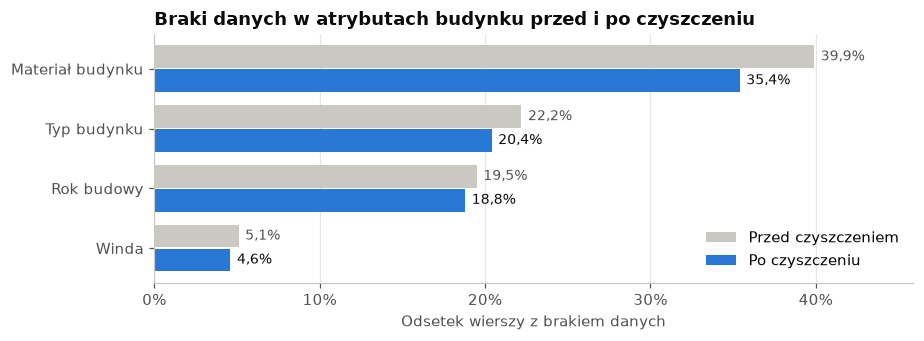

In [17]:
labels = {"build_year": "Rok budowy", "building_type": "Typ budynku",
          "building_material": "Materiał budynku", "has_elevator": "Winda"}
b = pd.Series({labels[c]: before[f"Braki: {c} (%)"] for c in cl.BUILDING_COLUMNS})
a = pd.Series({labels[c]: after[f"Braki: {c} (%)"] for c in cl.BUILDING_COLUMNS})
order = b.sort_values().index
y = range(len(order))

fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.barh([i + 0.2 for i in y], b[order], height=0.38, color=GREY, label="Przed czyszczeniem")
ax.barh([i - 0.2 for i in y], a[order], height=0.38, color=BLUE, label="Po czyszczeniu")
for i, name in enumerate(order):
    ax.text(b[name] + 0.4, i + 0.2, f"{b[name]:.1f}%".replace(".", ","), va="center", color=INK_2, fontsize=9)
    ax.text(a[name] + 0.4, i - 0.2, f"{a[name]:.1f}%".replace(".", ","), va="center", color=INK, fontsize=9)
ax.set_yticks(list(y), order)
ax.set_xlabel("Odsetek wierszy z brakiem danych")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlim(0, b.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title("Braki danych w atrybutach budynku przed i po czyszczeniu")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(IMG_DIR / "missing_values_before_after.png", bbox_inches="tight")
plt.show()

Tylko atrybuty budynku da się odzyskać w ten sposób. Pola opisujące samo mieszkanie zostają bez zmian: `floor` (16% braków), a zwłaszcza `condition` (74% braków) dotyczą konkretnego mieszkania, więc nie można ich wziąć od sąsiadów – dlatego `condition` jest w analizie tylko atrybutem pomocniczym.

## Zapis czystych tabel

In [18]:
cl.save_tables(tables, CLEAN_DIR)

,file,rows,columns,size_mb
0,listings.csv,128608,42,41.2
1,sale_snapshots.csv,192356,4,11.9
2,rent_snapshots.csv,70016,4,4.0
3,cities.csv,15,7,0.0
